# EC3278 Discrete Structure Mini Project 

This notebook implements the four tasks in the assignment brief using **real or realistic data**:

| Task | Data used |
|---|---|
| 1. Social network analysis | Zachary's Karate Club (real data, 34 people; Zachary, 1977; built into networkx) |
| 2. Shortest path | Kathmandu road network (landmarks; estimated distances in km from Google Maps) |
| 3. Minimum spanning tree | Network of 10 Nepali cities (estimated road distances in km from Google Maps) |
| 4. Eulerian / Hamiltonian | Garbage-collection street map + TSP over Nepali cities |

**Key points:** Dijkstra, Bellman-Ford, Prim, Kruskal, Hierholzer (Eulerian trail) and brute-force TSP are all. networkx is used only to *verify* the results and to draw the graphs.

Run the cells from top to bottom. Required libraries: `networkx`, `matplotlib`.

> **Note on data:** all road distances are **estimated driving distances from Google Maps, rounded**. They are approximations for illustration, not survey data. Full references are in the last cell.

In [8]:
"""
EC3278 Discrete Structure Mini Project
Requirements: Python 3, networkx, matplotlib
Works in Google Colab AND on a local computer.
"""
# ---------- Imports ----------
import heapq                      # priority queue (min-heap) used by Dijkstra and Prim
import math                       # math helpers
import os                         # to create the output folder
import random                     # random graphs for the scaling experiment
from itertools import permutations  # all orderings of cities for brute-force TSP
from time import perf_counter     # accurate timer for performance comparison
import networkx as nx             # graph library (drawing + verification only)
import matplotlib.pyplot as plt   # plotting

# ---------- Output folder ----------
# "graph_images" is created next to the notebook, so it works anywhere
# (Colab, Jupyter, VS Code). All figures are saved here as PNG files.
OUTPUT_DIR = "graph_images"
os.makedirs(OUTPUT_DIR, exist_ok=True)


def save_graph(G, filename, pos, title, edge_labels=None, highlight_edges=None,
               node_colors=None, node_size=1000, edge_color="gray", font_size=10):
    """Draw graph G, save it as a PNG, and show it.

    G               : networkx graph to draw
    filename        : name of the PNG file (saved in OUTPUT_DIR)
    pos             : dictionary {node: (x, y)} giving each node's position
    title           : title shown above the figure
    edge_labels     : optional {(u, v): label}, usually the edge weights
    highlight_edges : optional list of edges drawn thick and green
                      (used for shortest paths, MST edges, trails, tours)
    node_colors     : optional colour (or list of colours) for the nodes
    """
    plt.figure(figsize=(10, 7))
    nx.draw_networkx_nodes(G, pos, node_color=node_colors or "#b9d7ea",
                           node_size=node_size, edgecolors="#24445c", linewidths=1.2)
    nx.draw_networkx_labels(G, pos, font_size=font_size, font_weight="bold")

    # Edges that are NOT highlighted are drawn thin and grey.
    # An undirected edge can be stored as (u, v) or (v, u), so check both.
    normal = [e for e in G.edges() if not highlight_edges or
              (e not in highlight_edges and (e[1], e[0]) not in highlight_edges)]
    nx.draw_networkx_edges(G, pos, edgelist=normal, width=1.5, edge_color=edge_color)

    # Highlighted edges are drawn thick and green so they stand out.
    if highlight_edges:
        nx.draw_networkx_edges(G, pos, edgelist=highlight_edges, width=3.5,
                               edge_color="#1f9d55")
    if edge_labels is not None:
        nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)
    plt.title(title, fontsize=13, weight="bold")
    plt.axis("off")
    plt.tight_layout()
    path = os.path.join(OUTPUT_DIR, filename)
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close()
    print("Saved:", path)


def path_edges(path):
    """Convert a list of nodes [a, b, c] into a list of edges [(a, b), (b, c)]."""
    return list(zip(path[:-1], path[1:]))

## Task 1 — Social Network Analysis

**Model:** each person is a **vertex**, each mutual friendship is an **undirected edge**.

**Dataset:** *Zachary's Karate Club* (Zachary, 1977; reference at the end of this notebook). It records friendships between 34 members of a university karate club that later split into two groups (Mr. Hi's group and the Officer's group). It is the standard example for social network analysis, so we can compare our results with published ones.

**Measures used**
- **Degree** – number of direct friends (who is most popular).
- **Density** – fraction of all possible friendships that exist.
- **Connected components** – is everyone reachable from everyone else?
- **Clustering coefficient** – how often a person's friends are also friends with each other.
- **Betweenness centrality** – how often a person lies on shortest paths between others (a "bridge" or "broker").
- **Closeness centrality** – how near a person is to everyone else.
- **Communities** – groups of people more connected inside than outside.


TASK 1 — SOCIAL NETWORK (Zachary's Karate Club)
Vertices: 34 | Edges: 78
Density: 0.139
Connected components: 1
Average clustering coefficient: 0.571
Diameter: 5 | Average shortest path length: 2.408
Top 5 by degree      : [(33, 17), (0, 16), (32, 12), (2, 10), (1, 9)]
Top 5 by betweenness : [(0, 0.438), (33, 0.304), (32, 0.145), (2, 0.144), (31, 0.138)]
Top 5 by closeness   : [(0, 0.569), (2, 0.559), (33, 0.55), (31, 0.541), (8, 0.516)]
Communities found: 3
  Community 1 (17 members): [8, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
  Community 2 (9 members): [1, 2, 3, 7, 9, 12, 13, 17, 21]
  Community 3 (8 members): [0, 4, 5, 6, 10, 11, 16, 19]
Real club split: {'Mr. Hi': 17, 'Officer': 17}
Shortest path Mr. Hi (0) to Officer (33): [0, 8, 33]

Interpretation: member 33 has the most friends (degree 17); member 0 is the strongest bridge (betweenness 0.438).


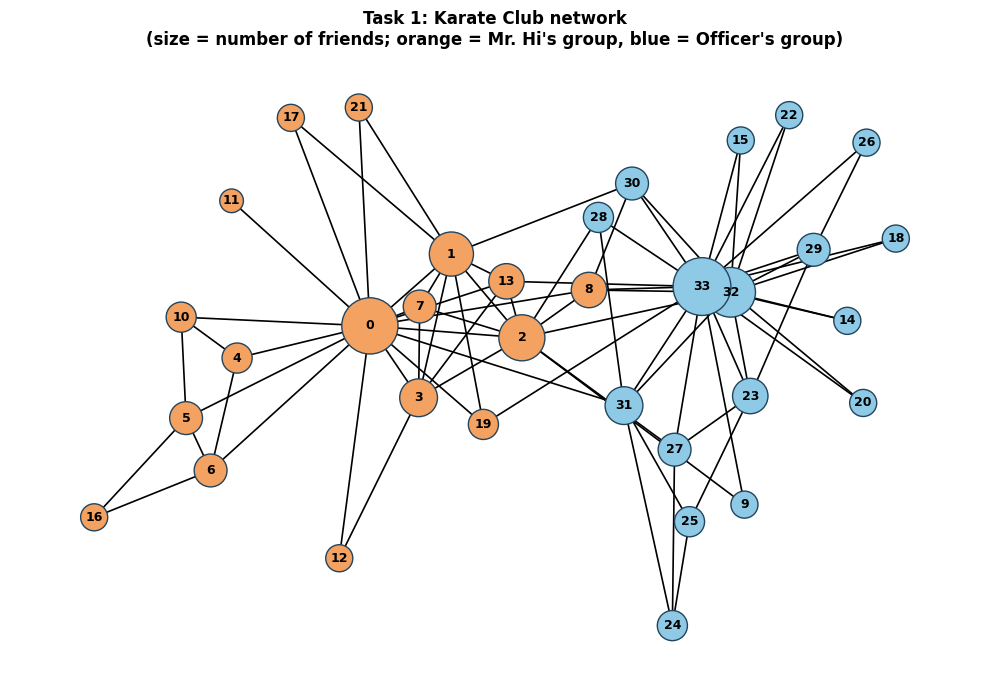

Saved: graph_images/figure1_social_network.png


In [9]:
# ============================================================
# TASK 1 — SOCIAL NETWORK ANALYSIS (Zachary's Karate Club)
# ============================================================
S = nx.karate_club_graph()   # real dataset: 34 members, 78 friendships

# ----- Basic measures -----
degrees     = dict(S.degree())                         # number of friends of each member
density     = nx.density(S)                            # actual edges / possible edges
components  = list(nx.connected_components(S))         # groups of mutually reachable people
clustering  = nx.average_clustering(S)                 # average "friends-of-friends are friends" score
betweenness = nx.betweenness_centrality(S, normalized=True)  # bridge score
closeness   = nx.closeness_centrality(S)               # nearness to everyone else
diameter    = nx.diameter(S)                           # longest shortest-path (valid: graph is connected)
avg_path    = nx.average_shortest_path_length(S)       # typical separation between two people

def top(d, k=5):
    """Return the k largest items of a dictionary as (node, rounded value) pairs."""
    return [(n, round(v, 3)) for n, v in sorted(d.items(), key=lambda x: -x[1])[:k]]

print("\nTASK 1 — SOCIAL NETWORK (Zachary's Karate Club)")
print("Vertices:", S.number_of_nodes(), "| Edges:", S.number_of_edges())
print("Density:", round(density, 3))
print("Connected components:", len(components))
print("Average clustering coefficient:", round(clustering, 3))
print("Diameter:", diameter, "| Average shortest path length:", round(avg_path, 3))
print("Top 5 by degree      :", top(degrees))
print("Top 5 by betweenness :", top(betweenness))
print("Top 5 by closeness   :", top(closeness))

# ----- Communities -----
# Greedy modularity finds groups that are densely connected internally.
communities = list(nx.community.greedy_modularity_communities(S))
print("Communities found:", len(communities))
for i, c in enumerate(communities, 1):
    print(f"  Community {i} ({len(c)} members):", sorted(c))

# Compare with the REAL split recorded in the dataset ("club" attribute).
real_split = {}
for n, data in S.nodes(data=True):
    real_split.setdefault(data["club"], []).append(n)
print("Real club split:", {k: len(v) for k, v in real_split.items()})

# ----- Shortest path (degrees of separation) between the two leaders -----
# Node 0 = Mr. Hi (instructor), node 33 = the Officer (administrator).
print("Shortest path Mr. Hi (0) to Officer (33):", nx.shortest_path(S, 0, 33))

# ----- Interpretation printed for the report -----
hub = max(degrees, key=degrees.get)
broker = max(betweenness, key=betweenness.get)
print(f"\nInterpretation: member {hub} has the most friends (degree {degrees[hub]}); "
      f"member {broker} is the strongest bridge (betweenness {betweenness[broker]:.3f}).")

# ----- Figure: node size = degree, colour = real club -----
pos1 = nx.spring_layout(S, seed=7)                      # fixed seed => same picture every run
colours = ["#f4a261" if S.nodes[n]["club"] == "Mr. Hi" else "#8ecae6" for n in S.nodes()]
sizes   = [200 + 90 * degrees[n] for n in S.nodes()]    # bigger circle = more friends
plt.figure(figsize=(10, 7))
nx.draw_networkx(S, pos1, node_color=colours, node_size=sizes,
                 edgecolors="#24445c", font_size=9, font_weight="bold", width=1.2)
plt.title("Task 1: Karate Club network\n(size = number of friends; orange = Mr. Hi's group, blue = Officer's group)",
          weight="bold")
plt.axis("off"); plt.tight_layout()
p = os.path.join(OUTPUT_DIR, "figure1_social_network.png")
plt.savefig(p, dpi=180, bbox_inches="tight"); plt.show(); plt.close()
print("Saved:", p)

## Task 2 — Shortest Path Algorithms

**Graph:** a road network of Kathmandu. Vertices are well-known landmarks/junctions; edge weights are **estimated driving distances in km, taken from Google Maps and rounded** (see *References and data sources* at the end).

### Two different problems, so two fair comparisons

Dijkstra and Nearest Neighbor do **not** solve the same problem, so they must not be compared on one task:

| | Problem | Algorithms |
|---|---|---|
| **Shortest path** | Find the shortest route from **one location to another**. Other places may be skipped. | **Dijkstra** vs **Bellman-Ford** (both are exact shortest-path methods) |
| **Visit-all tour** | Visit **every** stop once and return, as short as possible (TSP). | **Nearest Neighbor** vs **brute-force optimum** vs random tours |

- **Dijkstra** – always expands the closest unfinished vertex using a min-heap. Optimal for non-negative weights. Complexity **O((V + E) log V)**.
- **Bellman-Ford** – repeatedly relaxes *every* edge up to V − 1 times. Also optimal (and it can handle negative weights), but its worst case is worse: **O(V · E)**. On small sparse graphs, stopping early can make it about as fast as Dijkstra in practice (our measurements show this), which is why asymptotic complexity and measured time must both be reported.
- **Nearest Neighbor** – a greedy *visiting strategy*: from the current stop, always go to the closest unvisited stop. It does not search for a shortest route between two places; it builds a tour, and the tour has **no optimality guarantee**. Complexity **O(n²)** for n stops.
- Dijkstra connects the two parts: it gives the road distance between every pair of stops, which the tour methods then use.

> **Reading the timings:** run times below are measurements from *this* computer and *this* Python implementation on small random test graphs. They illustrate how the methods behave; they are **not a proof** that one algorithm is always faster. Results change with hardware, language, graph shape and implementation.


TASK 2 — PART 1: SHORTEST PATH BETWEEN TWO LOCATIONS
Dijkstra, Bellman-Ford and networkx all agree: OK
Dijkstra     Thamel -> Bhaktapur: ['Thamel', 'Ratna Park', 'New Baneshwor', 'Koteshwor', 'Bhaktapur'] | 16.5 km
Bellman-Ford Thamel -> Bhaktapur: ['Thamel', 'Ratna Park', 'New Baneshwor', 'Koteshwor', 'Bhaktapur'] | 16.5 km
Both return the same optimal distance; they differ only in HOW MUCH WORK they do.


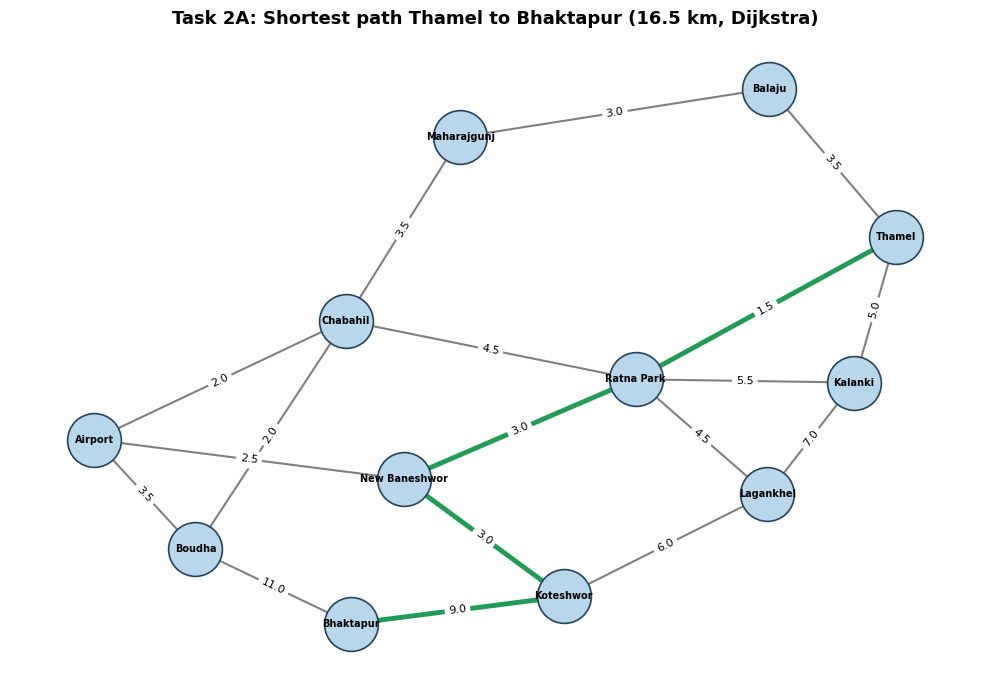

Saved: graph_images/figure2a_dijkstra_kathmandu.png

Average time over 2000 runs on the Kathmandu graph (this computer):
  Dijkstra = 35.2 microseconds | Bellman-Ford = 21.3 microseconds
n=  100 | Dijkstra     0.627 ms | Bellman-Ford     0.641 ms
n=  200 | Dijkstra     1.259 ms | Bellman-Ford     1.326 ms
n=  400 | Dijkstra     2.743 ms | Bellman-Ford     3.424 ms
n=  800 | Dijkstra     5.747 ms | Bellman-Ford     7.488 ms
n= 1600 | Dijkstra    15.173 ms | Bellman-Ford    16.919 ms


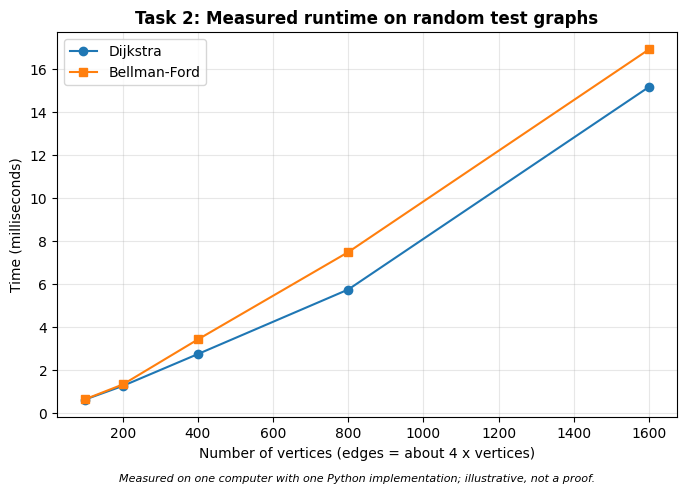

Saved: graph_images/figure2b_runtime_dijkstra_vs_bellmanford.png
Complexity: Dijkstra O((V+E) log V); Bellman-Ford O(V*E) in the worst case.
Observed: the measured times are close on these graphs (Bellman-Ford stops early, and Python's heap has
overhead). So the theoretical worst case is NOT visible here: timings depend on the test setup and are not proof.

TASK 2 — PART 2: VISIT-ALL TOUR (every stop once, then return)
Stops: ['Thamel', 'Ratna Park', 'New Baneshwor', 'Koteshwor', 'Boudha', 'Bhaktapur', 'Lagankhel', 'Maharajgunj']
Optimal tour (brute force, 5040 tours checked): Thamel -> Ratna Park -> Lagankhel -> New Baneshwor -> Koteshwor -> Bhaktapur -> Boudha -> Maharajgunj -> Thamel | 48.5 km
Nearest Neighbor tour: Thamel -> Ratna Park -> New Baneshwor -> Koteshwor -> Lagankhel -> Boudha -> Maharajgunj -> Bhaktapur -> Thamel | 63.0 km (29.9% longer than optimal)
Average of 1000 random tours: 67.5 km (best 48.5, worst 83.0)


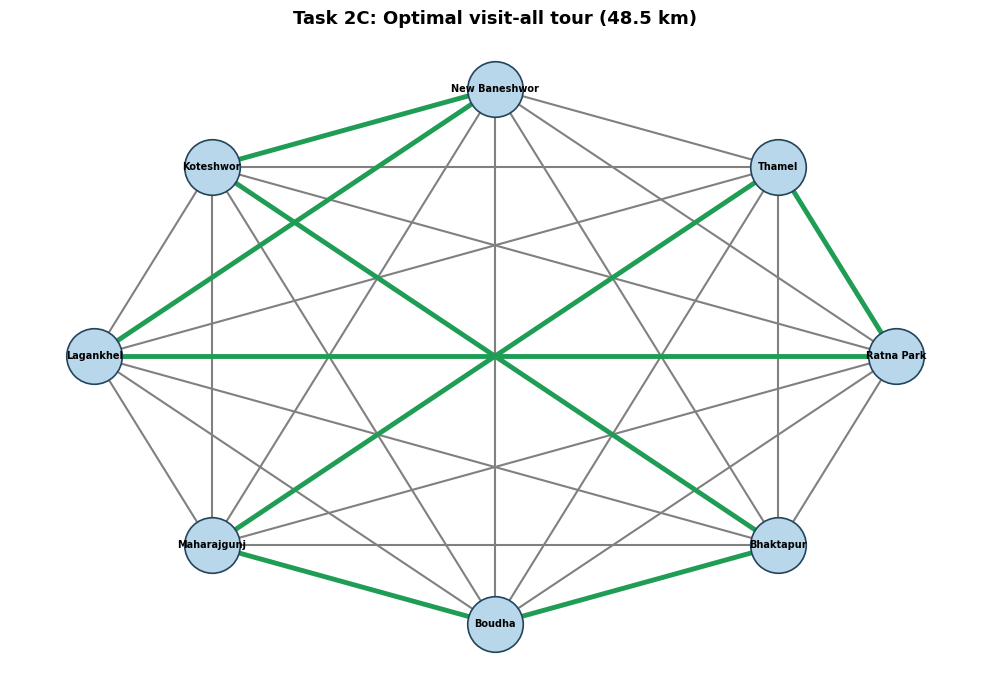

Saved: graph_images/figure2c_tour_optimal.png


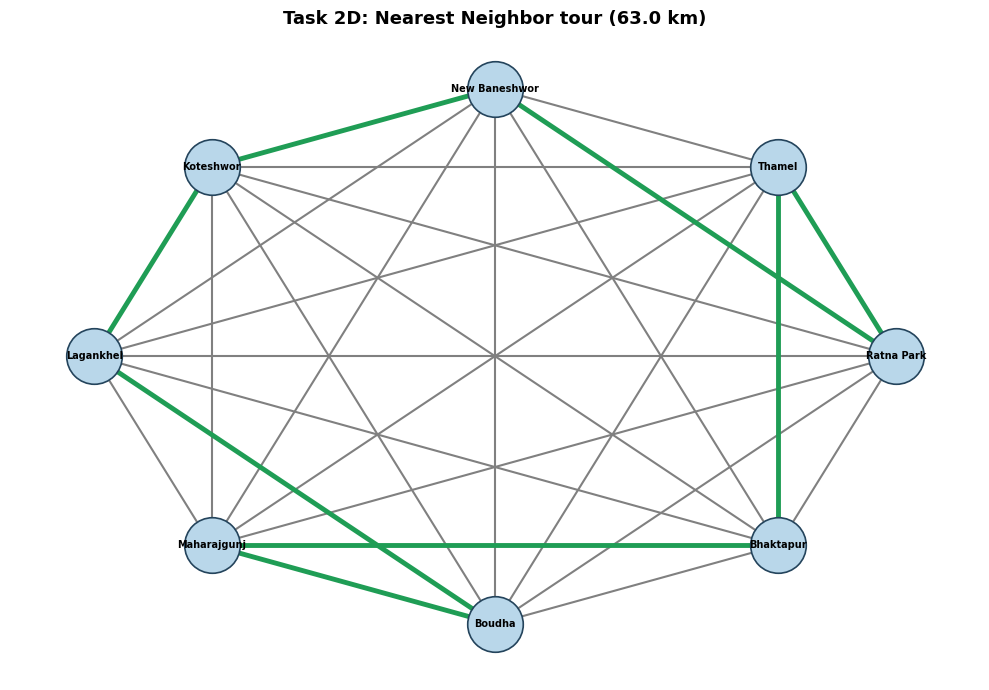

Saved: graph_images/figure2d_tour_nearest_neighbor.png
n=5 stops | NN    0.0553 ms | brute force      0.102 ms | NN is   0.0% longer than optimal
n=6 stops | NN    0.0201 ms | brute force      0.488 ms | NN is   0.0% longer than optimal
n=7 stops | NN    0.0217 ms | brute force      3.745 ms | NN is   0.0% longer than optimal
n=8 stops | NN    0.0418 ms | brute force     33.704 ms | NN is   4.9% longer than optimal
n=9 stops | NN    0.0723 ms | brute force    225.481 ms | NN is   5.7% longer than optimal


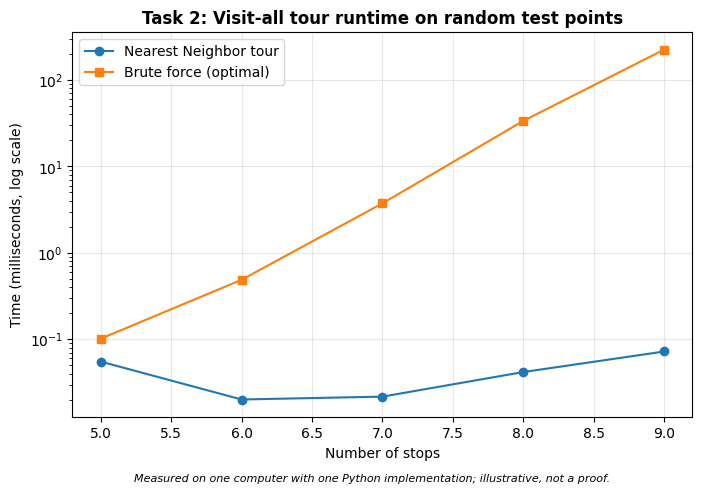

Saved: graph_images/figure2e_runtime_tour_methods.png

Complexity: Nearest Neighbor O(n^2); brute force O((n-1)! * n).
Conclusion: Dijkstra answers 'shortest route between two places' exactly. For 'visit every stop',
Nearest Neighbor is much cheaper than brute force but may give a longer tour, and it comes with
no guarantee. The timings are measurements from this test setup, not proof about all inputs.


In [10]:
# ============================================================
# TASK 2 — SHORTEST PATH (Dijkstra vs Bellman-Ford)
#          and VISIT-ALL TOURS (Nearest Neighbor vs optimum)
# ============================================================

# ---------- Kathmandu road network ----------
# Edge weights = estimated driving distance in km from Google Maps, rounded.
K = nx.Graph()
kathmandu_edges = [
    ("Thamel", "Ratna Park", 1.5),   ("Thamel", "Balaju", 3.5),
    ("Thamel", "Kalanki", 5.0),      ("Ratna Park", "New Baneshwor", 3.0),
    ("Ratna Park", "Chabahil", 4.5), ("Ratna Park", "Lagankhel", 4.5),
    ("Ratna Park", "Kalanki", 5.5),  ("New Baneshwor", "Koteshwor", 3.0),
    ("New Baneshwor", "Airport", 2.5), ("Airport", "Chabahil", 2.0),
    ("Chabahil", "Boudha", 2.0),     ("Chabahil", "Maharajgunj", 3.5),
    ("Balaju", "Maharajgunj", 3.0),  ("Koteshwor", "Bhaktapur", 9.0),
    ("Koteshwor", "Lagankhel", 6.0), ("Boudha", "Bhaktapur", 11.0),
    ("Kalanki", "Lagankhel", 7.0),   ("Airport", "Boudha", 3.5),
]
K.add_weighted_edges_from(kathmandu_edges)


def dijkstra(G, source):
    """Dijkstra's algorithm (min-heap version).

    Returns (dist, prev):
      dist[v] = length of the shortest path from source to v
      prev[v] = the vertex just before v on that shortest path
    Idea: keep a heap of (distance, vertex). Pop the closest vertex; it is now
    final. Try to improve ("relax") the distance of each of its neighbours.
    Works only for NON-NEGATIVE edge weights.
    """
    dist = {v: math.inf for v in G.nodes()}   # start: every vertex is "infinitely far"
    prev = {v: None for v in G.nodes()}       # to rebuild the path later
    dist[source] = 0
    heap = [(0, source)]                      # (distance so far, vertex)
    while heap:
        d, u = heapq.heappop(heap)            # closest vertex not yet finalised
        if d > dist[u]:                       # stale heap entry -> a better one was already used
            continue
        for v in G.neighbors(u):              # relax every edge (u, v)
            nd = d + G[u][v]["weight"]
            if nd < dist[v]:                  # found a shorter way to v
                dist[v] = nd
                prev[v] = u
                heapq.heappush(heap, (nd, v))
    return dist, prev


def bellman_ford(G, source):
    """Bellman-Ford algorithm: a second, independent exact shortest-path method.

    Repeat up to V-1 times: try to improve the distance across EVERY edge.
    Stop early if a whole pass changes nothing. Slower than Dijkstra (O(V*E))
    because it re-checks all edges each pass, but it does not need a heap.
    """
    dist = {v: math.inf for v in G.nodes()}
    prev = {v: None for v in G.nodes()}
    dist[source] = 0
    edges = [(u, v, d["weight"]) for u, v, d in G.edges(data=True)]
    for _ in range(G.number_of_nodes() - 1):
        changed = False
        for u, v, w in edges:                 # roads are two-way, so test both directions
            if dist[u] + w < dist[v]:
                dist[v] = dist[u] + w; prev[v] = u; changed = True
            if dist[v] + w < dist[u]:
                dist[u] = dist[v] + w; prev[u] = v; changed = True
        if not changed:                       # nothing improved -> distances are final
            break
    return dist, prev


def rebuild_path(prev, target):
    """Follow the 'prev' pointers backwards from target to the source."""
    path = []
    while target is not None:
        path.append(target)
        target = prev[target]
    return path[::-1]                         # reverse so it reads source -> target


print("\nTASK 2 — PART 1: SHORTEST PATH BETWEEN TWO LOCATIONS")

# ---------- A) Dijkstra vs Bellman-Ford on the Kathmandu graph ----------
src, dst = "Thamel", "Bhaktapur"
dist, prev = dijkstra(K, src)
bf_dist, bf_prev = bellman_ford(K, src)
d_path = rebuild_path(prev, dst)
bf_path = rebuild_path(bf_prev, dst)

# VERIFY: both   methods must agree with each other and with networkx.
nx_len = nx.shortest_path_length(K, src, dst, weight="weight")
assert abs(dist[dst] - nx_len) < 1e-9 and abs(bf_dist[dst] - nx_len) < 1e-9
assert all(abs(dist[v] - bf_dist[v]) < 1e-9 for v in K.nodes())
print("Dijkstra, Bellman-Ford and networkx all agree: OK")
print(f"Dijkstra     {src} -> {dst}: {d_path} | {dist[dst]} km")
print(f"Bellman-Ford {src} -> {dst}: {bf_path} | {bf_dist[dst]} km")
print("Both return the same optimal distance; they differ only in HOW MUCH WORK they do.")

posK = nx.spring_layout(K, seed=3, k=1.2)
labK = nx.get_edge_attributes(K, "weight")
save_graph(K, "figure2a_dijkstra_kathmandu.png", posK,
           f"Task 2A: Shortest path {src} to {dst} ({dist[dst]} km, Dijkstra)",
           labK, path_edges(d_path), node_size=1500, font_size=7)

# ---------- B) Timing on the SAME query (Dijkstra vs Bellman-Ford) ----------
# One run on a tiny graph is too fast and noisy, so repeat many times and average.
REPEATS = 2000
t0 = perf_counter()
for _ in range(REPEATS):
    dijkstra(K, src)
t_dij = (perf_counter() - t0) / REPEATS
t0 = perf_counter()
for _ in range(REPEATS):
    bellman_ford(K, src)
t_bf = (perf_counter() - t0) / REPEATS
print(f"\nAverage time over {REPEATS} runs on the Kathmandu graph (this computer):")
print(f"  Dijkstra = {t_dij * 1e6:.1f} microseconds | Bellman-Ford = {t_bf * 1e6:.1f} microseconds")

# ---------- C) How runtime grows with graph size ----------
def random_weighted_graph(n, seed):
    """Random connected graph with about 4n edges and weights 1..20."""
    rnd = random.Random(seed)
    G = nx.gnm_random_graph(n, 4 * n, seed=seed)
    comps = [list(c) for c in nx.connected_components(G)]
    for a, b in zip(comps[:-1], comps[1:]):   # join components so the graph is connected
        G.add_edge(a[0], b[0])
    for u, v in G.edges():
        G[u][v]["weight"] = rnd.randint(1, 20)
    return G

sizes_n = [100, 200, 400, 800, 1600]
times_dij, times_bf = [], []
for n in sizes_n:
    G = random_weighted_graph(n, seed=n)
    t0 = perf_counter(); dd, _ = dijkstra(G, 0); times_dij.append(perf_counter() - t0)
    t0 = perf_counter(); bb, _ = bellman_ford(G, 0); times_bf.append(perf_counter() - t0)
    assert all(abs(dd[v] - bb[v]) < 1e-9 for v in G.nodes())   # same answers every time
    print(f"n={n:5d} | Dijkstra {times_dij[-1]*1000:9.3f} ms | Bellman-Ford {times_bf[-1]*1000:9.3f} ms")

plt.figure(figsize=(8, 5))
plt.plot(sizes_n, [t * 1000 for t in times_dij], "o-", label="Dijkstra")
plt.plot(sizes_n, [t * 1000 for t in times_bf], "s-", label="Bellman-Ford")
plt.xlabel("Number of vertices (edges = about 4 x vertices)"); plt.ylabel("Time (milliseconds)")
plt.title("Task 2: Measured runtime on random test graphs", weight="bold")
plt.figtext(0.5, -0.02, "Measured on one computer with one Python implementation; illustrative, not a proof.",
            ha="center", fontsize=8, style="italic")
plt.legend(); plt.grid(alpha=0.3)
p = os.path.join(OUTPUT_DIR, "figure2b_runtime_dijkstra_vs_bellmanford.png")
plt.savefig(p, dpi=180, bbox_inches="tight"); plt.show(); plt.close()
print("Saved:", p)
print("Complexity: Dijkstra O((V+E) log V); Bellman-Ford O(V*E) in the worst case.")
print("Observed: the measured times are close on these graphs (Bellman-Ford stops early, and Python's heap has")
print("overhead). So the theoretical worst case is NOT visible here: timings depend on the test setup and are not proof.")

# ============================================================
# PART 2 — VISIT-ALL TOURS: Nearest Neighbor vs optimum (same requirement)
# ============================================================
print("\nTASK 2 — PART 2: VISIT-ALL TOUR (every stop once, then return)")

def tour_cost(route, G):
    """Total length of a route (list of stops) in complete graph G."""
    return sum(G[route[i]][route[i + 1]]["weight"] for i in range(len(route) - 1))


def tsp_nearest_neighbor(G, start):
    """Nearest Neighbor tour: always travel to the closest stop not yet visited,
    then return to the start. A greedy heuristic: fast, but not guaranteed optimal."""
    route, left = [start], set(G.nodes()) - {start}
    while left:
        nxt = min(left, key=lambda v: G[route[-1]][v]["weight"])
        route.append(nxt); left.remove(nxt)
    route.append(start)
    return route


def tsp_brute_force(G, start):
    """Try every ordering of the other n-1 stops; return (best_cost, best_route, count)."""
    others = [v for v in G.nodes() if v != start]
    best_cost, best_route, count = math.inf, None, 0
    for perm in permutations(others):
        route = (start,) + perm + (start,)
        c = tour_cost(route, G); count += 1
        if c < best_cost:
            best_cost, best_route = c, route
    return best_cost, list(best_route), count


# 8 stops. The distance between two stops is the SHORTEST ROAD distance found by
# Dijkstra, so every pair has a distance (a complete graph). This is how the two
# algorithms work together: Dijkstra measures distances, the tour methods order the stops.
stops = ["Thamel", "Ratna Park", "New Baneshwor", "Koteshwor",
         "Boudha", "Bhaktapur", "Lagankhel", "Maharajgunj"]
KT = nx.Graph()
for a in stops:
    da, _ = dijkstra(K, a)
    for b in stops:
        if a < b:
            KT.add_edge(a, b, weight=da[b])

opt_cost, opt_tour, n_tours = tsp_brute_force(KT, "Thamel")
nn_t = tsp_nearest_neighbor(KT, "Thamel")
nn_c = tour_cost(nn_t, KT)

# Baseline: average length of random tours (shows how much any method improves on luck).
rnd = random.Random(1)
rand_costs = []
for _ in range(1000):
    order = stops[1:]; rnd.shuffle(order)
    rand_costs.append(tour_cost(["Thamel"] + order + ["Thamel"], KT))

print(f"Stops: {stops}")
print(f"Optimal tour (brute force, {n_tours} tours checked): {' -> '.join(opt_tour)} | {opt_cost:.1f} km")
print(f"Nearest Neighbor tour: {' -> '.join(nn_t)} | {nn_c:.1f} km "
      f"({(nn_c / opt_cost - 1) * 100:.1f}% longer than optimal)")
print(f"Average of 1000 random tours: {sum(rand_costs) / len(rand_costs):.1f} km "
      f"(best {min(rand_costs):.1f}, worst {max(rand_costs):.1f})")
nn_gap = (nn_c / opt_cost - 1) * 100

posKT = nx.circular_layout(KT)
save_graph(KT, "figure2c_tour_optimal.png", posKT,
           f"Task 2C: Optimal visit-all tour ({opt_cost:.1f} km)", None,
           path_edges(opt_tour), node_size=1600, font_size=7)
save_graph(KT, "figure2d_tour_nearest_neighbor.png", posKT,
           f"Task 2D: Nearest Neighbor tour ({nn_c:.1f} km)", None,
           path_edges(nn_t), node_size=1600, font_size=7)

# ---------- Scaling: NN tour vs brute force on random points ----------
# Stops are random points in a square; distance = straight-line (Euclidean).
def random_points_graph(n, seed):
    rnd = random.Random(seed)
    pts = [(rnd.random() * 100, rnd.random() * 100) for _ in range(n)]
    G = nx.Graph()
    for i in range(n):
        for j in range(i + 1, n):
            G.add_edge(i, j, weight=math.dist(pts[i], pts[j]))
    return G

ns = [5, 6, 7, 8, 9]
t_nn_list, t_bf_list, gap_list = [], [], []
for n in ns:
    G = random_points_graph(n, seed=n)
    t0 = perf_counter(); r = tsp_nearest_neighbor(G, 0); t_nn_list.append(perf_counter() - t0)
    t0 = perf_counter(); bc, _, _ = tsp_brute_force(G, 0); t_bf_list.append(perf_counter() - t0)
    gap_list.append((tour_cost(r, G) / bc - 1) * 100)
    print(f"n={n} stops | NN {t_nn_list[-1]*1000:9.4f} ms | brute force {t_bf_list[-1]*1000:10.3f} ms | "
          f"NN is {gap_list[-1]:5.1f}% longer than optimal")

plt.figure(figsize=(8, 5))
plt.semilogy(ns, [t * 1000 for t in t_nn_list], "o-", label="Nearest Neighbor tour")
plt.semilogy(ns, [t * 1000 for t in t_bf_list], "s-", label="Brute force (optimal)")
plt.xlabel("Number of stops"); plt.ylabel("Time (milliseconds, log scale)")
plt.title("Task 2: Visit-all tour runtime on random test points", weight="bold")
plt.figtext(0.5, -0.02, "Measured on one computer with one Python implementation; illustrative, not a proof.",
            ha="center", fontsize=8, style="italic")
plt.legend(); plt.grid(alpha=0.3)
p = os.path.join(OUTPUT_DIR, "figure2e_runtime_tour_methods.png")
plt.savefig(p, dpi=180, bbox_inches="tight"); plt.show(); plt.close()
print("Saved:", p)

print("\nComplexity: Nearest Neighbor O(n^2); brute force O((n-1)! * n).")
print("Conclusion: Dijkstra answers 'shortest route between two places' exactly. For 'visit every stop',")
print("Nearest Neighbor is much cheaper than brute force but may give a longer tour, and it comes with")
print("no guarantee. The timings are measurements from this test setup, not proof about all inputs.")

## Task 3 — Minimum Spanning Tree (Prim and Kruskal)

**Scenario:** a telecom company wants to lay fibre-optic cable so that 10 Nepali cities are all connected, using the least total cable.

**Graph:** vertices are cities; edges are possible cable routes with **estimated road distances (km) from Google Maps, rounded** as cost.

**Algorithms**
- **Prim** – grow one tree from a start city; repeatedly add the cheapest edge leaving the tree. Complexity **O(E log V)** with a heap.
- **Kruskal** – sort all edges by cost; add an edge unless it would create a cycle (checked with Union-Find). Complexity **O(E log E)**.

An MST has exactly **V − 1 edges**, no cycles, and the smallest possible total cost.


TASK 3 — MINIMUM SPANNING TREE
Prim = Kruskal = networkx cost: OK
Cities: 10 | Possible links: 17
Total length if we built EVERY link: 3160 km
Prim    MST: [('Kathmandu', 'Hetauda', 130), ('Hetauda', 'Birgunj', 70), ('Birgunj', 'Janakpur', 140), ('Hetauda', 'Pokhara', 170), ('Pokhara', 'Butwal', 120), ('Janakpur', 'Biratnagar', 190), ('Biratnagar', 'Dharan', 50), ('Butwal', 'Nepalgunj', 200), ('Nepalgunj', 'Dhangadhi', 160)] 
        cost = 1230 km
Kruskal MST: [('Biratnagar', 'Dharan', 50), ('Hetauda', 'Birgunj', 70), ('Pokhara', 'Butwal', 120), ('Kathmandu', 'Hetauda', 130), ('Janakpur', 'Birgunj', 140), ('Nepalgunj', 'Dhangadhi', 160), ('Hetauda', 'Pokhara', 170), ('Janakpur', 'Biratnagar', 190), ('Butwal', 'Nepalgunj', 200)] 
        cost = 1230 km
MST has 9 edges = V-1 = 9
Saving: 1930 km of cable (61% less than building everything)

Kruskal step-by-step:
   ACCEPT Biratnagar-Dharan (50)
   ACCEPT Hetauda-Birgunj (70)
   ACCEPT Pokhara-Butwal (120)
   ACCEPT Kathmandu-Hetauda (13

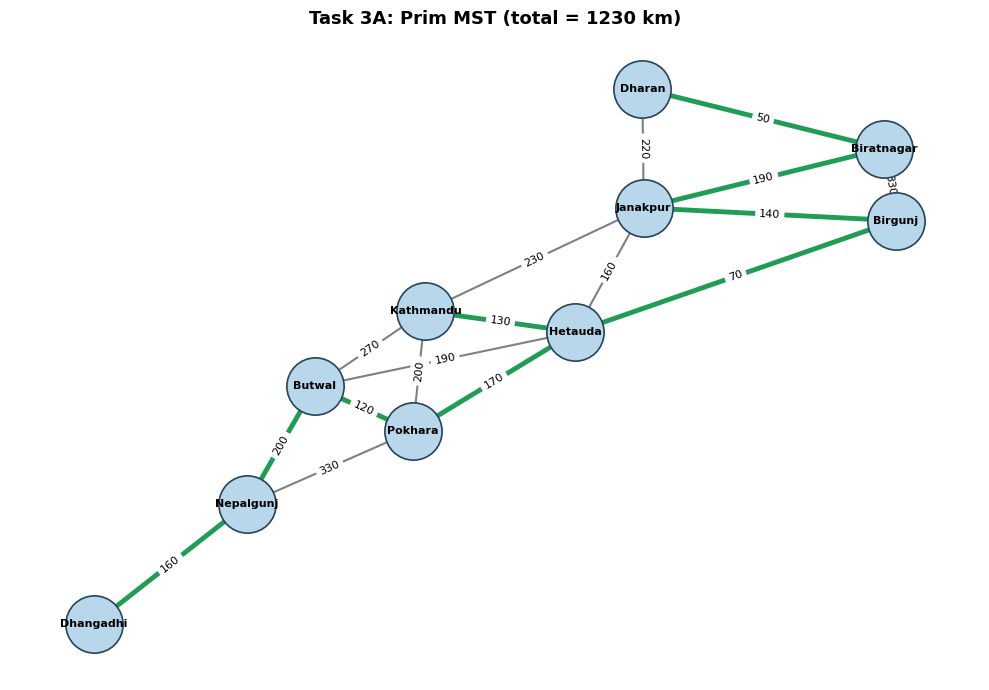

Saved: graph_images/figure3a_prim_mst.png


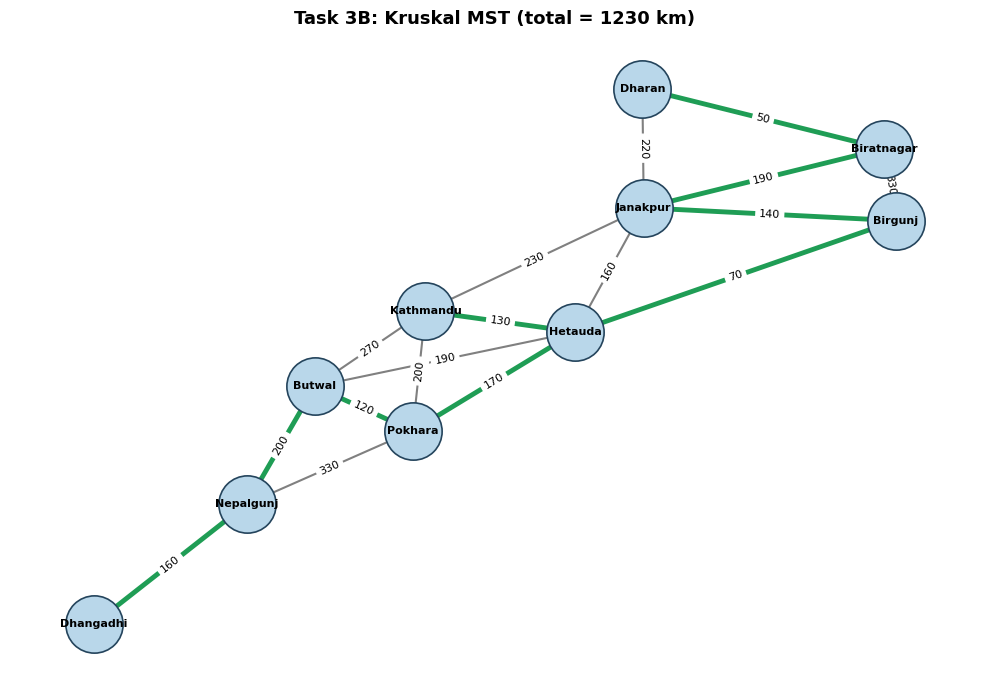

Saved: graph_images/figure3b_kruskal_mst.png


In [11]:
# ============================================================
# TASK 3 — PRIM AND KRUSKAL MST
# ============================================================

# ---------- Network of Nepali cities (estimated Google Maps road distances, km, rounded) ----------
M = nx.Graph()
city_links = [
    ("Kathmandu", "Hetauda", 130),  ("Kathmandu", "Pokhara", 200),
    ("Kathmandu", "Janakpur", 230), ("Hetauda", "Birgunj", 70),
    ("Hetauda", "Janakpur", 160),   ("Hetauda", "Butwal", 190),
    ("Birgunj", "Janakpur", 140),   ("Pokhara", "Butwal", 120),
    ("Pokhara", "Hetauda", 170),    ("Butwal", "Nepalgunj", 200),
    ("Janakpur", "Biratnagar", 190),("Biratnagar", "Dharan", 50),
    ("Biratnagar", "Birgunj", 330), ("Dharan", "Janakpur", 220),
    ("Nepalgunj", "Dhangadhi", 160),("Nepalgunj", "Pokhara", 330),
    ("Butwal", "Kathmandu", 270),
]
M.add_weighted_edges_from(city_links)


def prim_mst(G, start):
    """Prim's algorithm. Returns (list of MST edges (u, v, w), total cost).

    Keep a heap of edges that leave the growing tree. Always take the cheapest
    one; if it leads to a NEW city, add that city and push its edges.
    """
    in_tree = {start}                         # cities already connected
    heap = [(G[start][v]["weight"], start, v) for v in G.neighbors(start)]
    heapq.heapify(heap)
    edges, total = [], 0
    while heap and len(in_tree) < G.number_of_nodes():
        w, u, v = heapq.heappop(heap)         # cheapest edge leaving the tree
        if v in in_tree:                      # would form a cycle -> skip
            continue
        in_tree.add(v)
        edges.append((u, v, w)); total += w
        for x in G.neighbors(v):              # new frontier edges from v
            if x not in in_tree:
                heapq.heappush(heap, (G[v][x]["weight"], v, x))
    return edges, total


class UnionFind:
    """Union-Find (disjoint sets) used by Kruskal to detect cycles quickly."""
    def __init__(self, items):
        self.parent = {i: i for i in items}
        self.rank = {i: 0 for i in items}
    def find(self, x):                        # root of x's set (with path compression)
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x
    def union(self, a, b):                    # merge two sets; False if already same set
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False                      # same set => this edge would make a cycle
        if self.rank[ra] < self.rank[rb]:
            ra, rb = rb, ra
        self.parent[rb] = ra                  # attach the smaller tree under the bigger
        if self.rank[ra] == self.rank[rb]:
            self.rank[ra] += 1
        return True


def kruskal_mst(G):
    """Kruskal's algorithm. Returns (list of MST edges, total cost, step log)."""
    uf = UnionFind(G.nodes())
    edges, total, log = [], 0, []
    # sort every edge by weight (ties broken by names so the result is repeatable)
    for u, v, d in sorted(G.edges(data=True), key=lambda e: (e[2]["weight"], e[0], e[1])):
        if uf.union(u, v):                    # joins two different components -> accept
            edges.append((u, v, d["weight"])); total += d["weight"]
            log.append(f"ACCEPT {u}-{v} ({d['weight']})")
        else:                                 # both ends already connected -> reject
            log.append(f"reject {u}-{v} ({d['weight']}) would form a cycle")
    return edges, total, log


print("\nTASK 3 — MINIMUM SPANNING TREE")
assert nx.is_connected(M), "All cities must be reachable for a spanning tree to exist"
full_weight = sum(d["weight"] for _, _, d in M.edges(data=True))

prim_edges, prim_cost = prim_mst(M, "Kathmandu")
kru_edges, kru_cost, kru_log = kruskal_mst(M)

# VERIFY against networkx (costs must match; the trees can differ only when weights tie)
nx_cost = sum(d["weight"] for _, _, d in nx.minimum_spanning_tree(M).edges(data=True))
assert prim_cost == kru_cost == nx_cost
print("Prim = Kruskal = networkx cost: OK")

print("Cities:", M.number_of_nodes(), "| Possible links:", M.number_of_edges())
print("Total length if we built EVERY link:", full_weight, "km")
print("Prim    MST:", prim_edges, "\n        cost =", prim_cost, "km")
print("Kruskal MST:", kru_edges, "\n        cost =", kru_cost, "km")
print(f"MST has {len(prim_edges)} edges = V-1 = {M.number_of_nodes() - 1}")
print(f"Saving: {full_weight - prim_cost} km of cable ({(1 - prim_cost / full_weight) * 100:.0f}% less than building everything)")
print("\nKruskal step-by-step:")
for line in kru_log:
    print("  ", line)

posM = nx.spring_layout(M, seed=21, k=1.4)
labM = nx.get_edge_attributes(M, "weight")
save_graph(M, "figure3a_prim_mst.png", posM, f"Task 3A: Prim MST (total = {prim_cost} km)",
           labM, [(u, v) for u, v, _ in prim_edges], node_size=1700, font_size=8)
save_graph(M, "figure3b_kruskal_mst.png", posM, f"Task 3B: Kruskal MST (total = {kru_cost} km)",
           labM, [(u, v) for u, v, _ in kru_edges], node_size=1700, font_size=8)

## Task 4 — Eulerian and Hamiltonian Paths

**Eulerian path (garbage collection).** A truck must drive along **every street (edge) exactly once**.
For a connected undirected graph:
- 0 odd-degree vertices → **Eulerian circuit** (start and end at the same place)
- exactly 2 odd-degree vertices → **Eulerian trail** (start at one odd vertex, end at the other)
- more than 2 → **no** Eulerian trail (some streets must be driven twice)

**Hamiltonian cycle (Travelling Salesman Problem).** A salesman must visit **every city exactly once** and return home, with the smallest total distance. Brute force checks all (n−1)! orders, which is only practical for small n because TSP is **NP-hard**.


TASK 4A — EULERIAN TRAIL (garbage collection)
Degrees: {'Depot': 2, 'A': 4, 'B': 3, 'C': 3, 'D': 4, 'E': 2}
Odd-degree vertices: ['B', 'C'] -> Eulerian trail
Truck route: B -> Depot -> A -> D -> E -> C -> D -> B -> A -> C
Verified: 9 streets, each used exactly once.


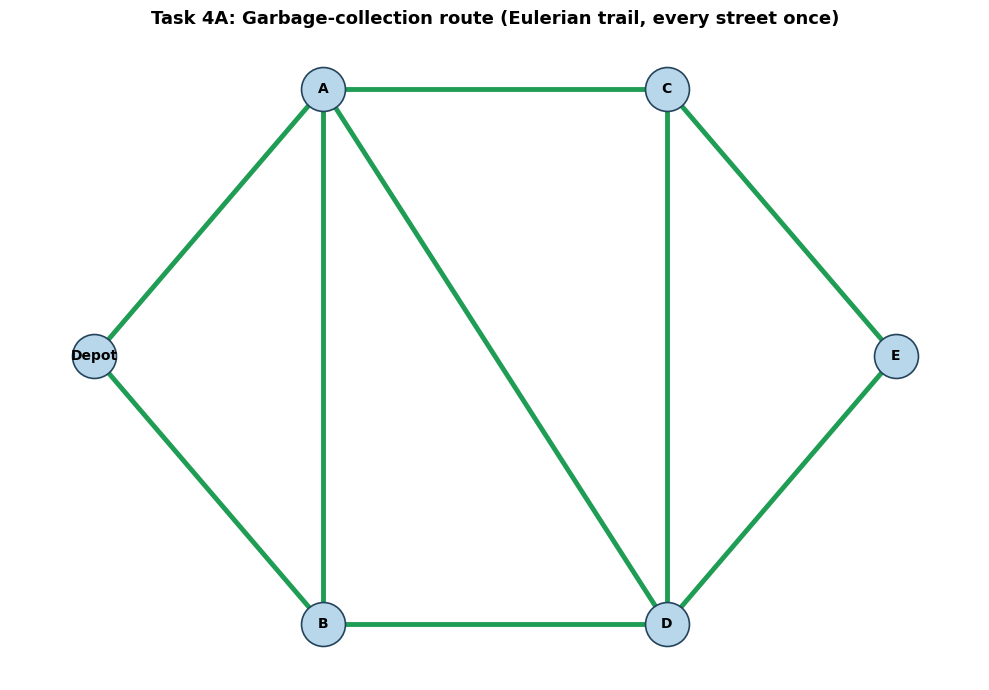

Saved: graph_images/figure4a_eulerian_trail.png

Non-Eulerian example degrees: {'P': 3, 'Q': 3, 'R': 3, 'S': 3}
Odd-degree vertices: ['P', 'Q', 'R', 'S'] -> Eulerian none | networkx agrees: True
Fix: the truck must repeat some streets (Chinese Postman idea).


In [12]:
# ============================================================
# TASK 4A — EULERIAN TRAIL: garbage collection (Hierholzer)
# ============================================================

def odd_vertices(G):
    """Vertices with an odd number of streets attached."""
    return [v for v, d in G.degree() if d % 2 == 1]


def euler_type(G):
    """Classify a graph using the odd-degree rule (graph must be connected)."""
    if not nx.is_connected(G):
        return "none (graph is not connected)"
    k = len(odd_vertices(G))
    return {0: "circuit", 2: "trail"}.get(k, "none")


def hierholzer(G):
    """Hierholzer's algorithm: build an Eulerian circuit/trail as a node list.

    Start at an odd vertex if there is one (needed for a trail), otherwise anywhere.
    Walk along unused edges; when stuck, back up and splice in the sub-tours.
    """
    odd = odd_vertices(G)
    start = odd[0] if odd else next(iter(G.nodes()))
    unused = {v: set(G.neighbors(v)) for v in G.nodes()}   # edges not yet driven
    stack, path = [start], []
    while stack:
        v = stack[-1]
        if unused[v]:                         # still an unused street at v
            w = unused[v].pop()               # drive along it
            unused[w].remove(v)               # an undirected edge is used from BOTH ends
            stack.append(w)
        else:                                 # stuck: this vertex is finished
            path.append(stack.pop())
    return path[::-1]


# Street map of a small neighbourhood: nodes = junctions, edges = streets.
E = nx.Graph()
E.add_edges_from([("Depot", "A"), ("Depot", "B"), ("A", "B"), ("A", "C"),
                  ("B", "D"), ("C", "D"), ("C", "E"), ("D", "E"), ("A", "D")])
print("\nTASK 4A — EULERIAN TRAIL (garbage collection)")
print("Degrees:", dict(E.degree()))
print("Odd-degree vertices:", odd_vertices(E), "-> Eulerian", euler_type(E))
trail = hierholzer(E)
print("Truck route:", " -> ".join(trail))
# VERIFY: the route must use every street exactly once.
used = [frozenset(e) for e in path_edges(trail)]
assert len(used) == E.number_of_edges() == len(set(used)), "route must use each street once"
assert nx.has_eulerian_path(E)
print(f"Verified: {len(used)} streets, each used exactly once.")

pos4 = {"Depot": (0, 0), "A": (1, 1), "B": (1, -1), "C": (2.5, 1), "D": (2.5, -1), "E": (3.5, 0)}
save_graph(E, "figure4a_eulerian_trail.png", pos4,
           "Task 4A: Garbage-collection route (Eulerian trail, every street once)",
           None, path_edges(trail))      # draws the trail the code actually computed

# A neighbourhood where it is IMPOSSIBLE (4 odd vertices): some street must be repeated.
N = nx.Graph()
# Four junctions, every pair joined by a street (like the Konigsberg bridges):
# all four junctions have degree 3 (odd), so no Eulerian trail can exist.
N.add_edges_from([("P", "Q"), ("P", "R"), ("P", "S"),
                  ("Q", "R"), ("Q", "S"), ("R", "S")])
print("\nNon-Eulerian example degrees:", dict(N.degree()))
print("Odd-degree vertices:", odd_vertices(N), "-> Eulerian", euler_type(N),
      "| networkx agrees:", not nx.has_eulerian_path(N))
print("Fix: the truck must repeat some streets (Chinese Postman idea).")


TASK 4B — TRAVELLING SALESPERSON PROBLEM
Cities: ['Kathmandu', 'Pokhara', 'Butwal', 'Hetauda', 'Birgunj', 'Janakpur', 'Biratnagar', 'Nepalgunj']
Hamiltonian cycles checked (start fixed): 5040 = 7!
OPTIMAL tour (brute force): Kathmandu -> Pokhara -> Nepalgunj -> Butwal -> Hetauda -> Birgunj -> Janakpur -> Biratnagar -> Kathmandu | 1730 km
Nearest Neighbor tour     : Kathmandu -> Hetauda -> Birgunj -> Janakpur -> Biratnagar -> Pokhara -> Butwal -> Nepalgunj -> Kathmandu | 1840 km (6.4% longer than optimal)
Brute force needs (n-1)! tours: n=8 -> 5,040; n=12 -> 39,916,800; n=20 -> ~1.2e17 (impossible).


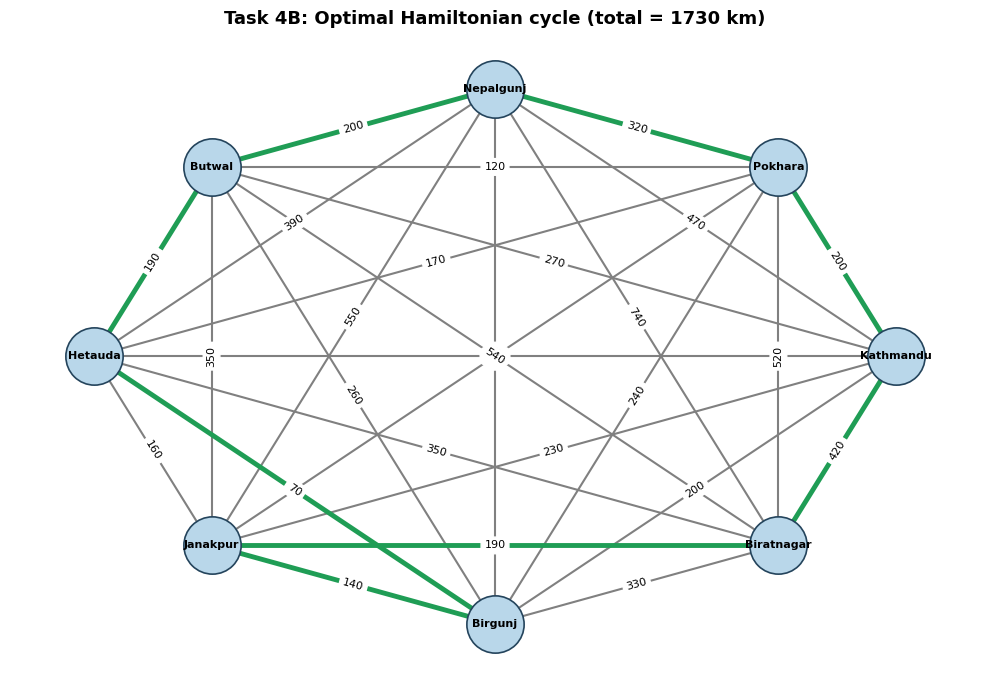

Saved: graph_images/figure4b_tsp_optimal_tour.png

SUMMARY
Task 1: Karate Club - 34 people, 78 friendships, density 0.139, most popular member = 33, strongest bridge = 0
Task 2: Dijkstra = Bellman-Ford = 16.5 km (Thamel->Bhaktapur); visit-all tour: optimal 48.5 km vs Nearest Neighbor 63.0 km (+29.9%)
Task 3: Prim cost = 1230 km; Kruskal cost = 1230 km (full network = 3160 km)
Task 4: Eulerian route uses all 9 streets once; optimal TSP = 1730 km
All figures saved to: /content/graph_images


In [13]:
# ============================================================
# TASK 4B — HAMILTONIAN CYCLE / TSP over Nepali cities (brute force)
# ============================================================
# Use 8 cities from the Task 3 map. Distance between two cities = shortest road
# distance found with our own Dijkstra, so every pair has a distance (complete graph).
tsp_cities = ["Kathmandu", "Pokhara", "Butwal", "Hetauda", "Birgunj",
              "Janakpur", "Biratnagar", "Nepalgunj"]
T = nx.Graph()
for a in tsp_cities:
    da, _ = dijkstra(M, a)
    for b in tsp_cities:
        if a < b:
            T.add_edge(a, b, weight=da[b])


# Brute force: fix the start (every cycle can be rotated to start there) and try
# every ordering of the other n-1 cities: (n-1)! = 5040 tours for n = 8.
start = "Kathmandu"
others = [v for v in T.nodes() if v != start]
best_cost, best_cycle, n_checked = math.inf, None, 0
for perm in permutations(others):
    route = (start,) + perm + (start,)
    c = tour_cost(route, T)
    n_checked += 1
    if c < best_cost:
        best_cost, best_cycle = c, route

# Nearest Neighbor heuristic (tsp_nearest_neighbor, defined in Task 2) for comparison.
nn_tour = tsp_nearest_neighbor(T, start)
nn_tour_cost = tour_cost(nn_tour, T)

print("\nTASK 4B — TRAVELLING SALESPERSON PROBLEM")
print("Cities:", tsp_cities)
print("Hamiltonian cycles checked (start fixed):", n_checked, "= 7!")
print("OPTIMAL tour (brute force):", " -> ".join(best_cycle), "|", best_cost, "km")
print("Nearest Neighbor tour     :", " -> ".join(nn_tour), "|", nn_tour_cost, "km",
      f"({(nn_tour_cost / best_cost - 1) * 100:.1f}% longer than optimal)")
print("Brute force needs (n-1)! tours: n=8 -> 5,040; n=12 -> 39,916,800; n=20 -> ~1.2e17 (impossible).")

posT = nx.circular_layout(T)
save_graph(T, "figure4b_tsp_optimal_tour.png", posT,
           f"Task 4B: Optimal Hamiltonian cycle (total = {best_cost} km)",
           nx.get_edge_attributes(T, "weight"), path_edges(best_cycle),
           node_size=1700, font_size=8)

# ---------- Summary of all results (copy these numbers into your report) ----------
print("\nSUMMARY")
print(f"Task 1: Karate Club - {S.number_of_nodes()} people, {S.number_of_edges()} friendships, "
      f"density {density:.3f}, most popular member = {hub}, strongest bridge = {broker}")
print(f"Task 2: Dijkstra = Bellman-Ford = {dist[dst]} km ({src}->{dst}); visit-all tour: optimal {opt_cost:.1f} km vs Nearest Neighbor {nn_c:.1f} km (+{nn_gap:.1f}%)")
print(f"Task 3: Prim cost = {prim_cost} km; Kruskal cost = {kru_cost} km (full network = {full_weight} km)")
print(f"Task 4: Eulerian route uses all {E.number_of_edges()} streets once; optimal TSP = {best_cost} km")
print("All figures saved to:", os.path.abspath(OUTPUT_DIR))

## References and data sources

**Datasets**
- Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. *Journal of Anthropological Research*, 33(4), 452–473. (Task 1 data, loaded with `nx.karate_club_graph()`.)

**Road distances (Tasks 2, 3 and 4)**
- All distances between Kathmandu landmarks and between Nepali cities are **estimates of driving distance read from Google Maps** (https://www.google.com/maps), **rounded** to 0.5 km (Kathmandu) or 10 km (between cities). They are not official survey data, and real distances vary with the route chosen. Date accessed: 17th October 2026.
- Task 2's random graphs and random points, and the small example graphs in Task 4, are **synthetic** data generated by the code.

**Software**
- Hagberg, A. A., Schult, D. A., & Swart, P. J. (2008). Exploring network structure, dynamics, and function using NetworkX. *Proceedings of the 7th Python in Science Conference (SciPy 2008)*, 11–15.
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering*, 9(3), 90–95.

**Algorithms**
- Dijkstra, E. W. (1959). A note on two problems in connexion with graphs. *Numerische Mathematik*, 1, 269–271.
- Bellman, R. (1958). On a routing problem. *Quarterly of Applied Mathematics*, 16(1), 87–90.
- Prim, R. C. (1957). Shortest connection networks and some generalizations. *Bell System Technical Journal*, 36(6), 1389–1401.
- Kruskal, J. B. (1956). On the shortest spanning subtree of a graph and the traveling salesman problem. *Proceedings of the American Mathematical Society*, 7(1), 48–50.
- Hierholzer, C. (1873). Ueber die Möglichkeit, einen Linienzug ohne Wiederholung und ohne Unterbrechung zu umfahren. *Mathematische Annalen*, 6, 30–32.